In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [3]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)

print(df.shape)
df.head()

(5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
categorical = list(df.select_dtypes(exclude='number').columns)
numerical = [c for c in df.select_dtypes(include='number').columns if c != 'converted']

print('categorical:', categorical)
print('numerical:  ', numerical)
print(df.isna().sum()[df.isna().sum() > 0])

categorical: ['lead_source', 'industry', 'employment_status', 'location']
numerical:   ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
lead_source          148
industry             240
employment_status    194
location             208
annual_income        369
lead_score            35
dtype: int64


In [6]:
for c in categorical:
    df[c] = df[c].fillna('NA')
for c in numerical:
    df[c] = df[c].fillna(0.0)

print('missing after fill:', df.isna().sum().sum())

missing after fill: 0


In [7]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

print(len(df_train), len(df_val), len(df_test))

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

3000 1000 1000


In [9]:
num_columns = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

num_scores = {}
for c in num_columns:
    a = roc_auc_score(y_train, df_train[c])
    if a < 0.5:
        a = roc_auc_score(y_train, -df_train[c])
    num_scores[c] = a
    print(f'{c:28s} {a:.3f}')

num_answer = max(num_scores, key=num_scores.get)
print('Answer:', num_answer)

lead_score                   0.788
number_of_courses_viewed     0.723
interaction_count            0.765
annual_income                0.608
Answer: lead_score


In [10]:
features = categorical + numerical

def train(df_tr, y_tr, C=1.0):
    dicts = df_tr[features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(df_, dv, model):
    X = dv.transform(df_[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

In [12]:
dv, model = train(df_train, y_train, C=1.0)
y_pred = predict(df_val, dv, model)

print('number of features:', len(dv.get_feature_names_out()))
num_auc = roc_auc_score(y_val, y_pred)
print('Answer:', round(num_auc, 3))

number of features: 28
Answer: 0.732


In [13]:
def metrics_table(y_true, y_score):
    rows = []
    for t in np.linspace(0, 1, 101):
        predict_positive = (y_score >= t)

        tp = (predict_positive & (y_true == 1)).sum()
        fp = (predict_positive & (y_true == 0)).sum()
        fn = (~predict_positive & (y_true == 1)).sum()

        p = tp / (tp + fp) if (tp + fp) > 0 else np.nan
        r = tp / (tp + fn)
        f1 = 2 * tp / (2 * tp + fp + fn)

        rows.append((t, p, r, f1))

    return pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])

scores = metrics_table(y_val, y_pred)
scores.iloc[::10].round(3)

,threshold,precision,recall,f1
0,0.0,0.586,1.000,0.739
10,0.1,0.586,1.000,0.739
20,0.2,0.586,1.000,0.739
30,0.3,0.593,1.000,0.744
40,0.4,0.613,0.978,0.753
50,0.5,0.644,0.906,0.753
60,0.6,0.706,0.780,0.741
70,0.7,0.791,0.531,0.635
80,0.8,0.858,0.237,0.372
90,0.9,0.950,0.032,0.063


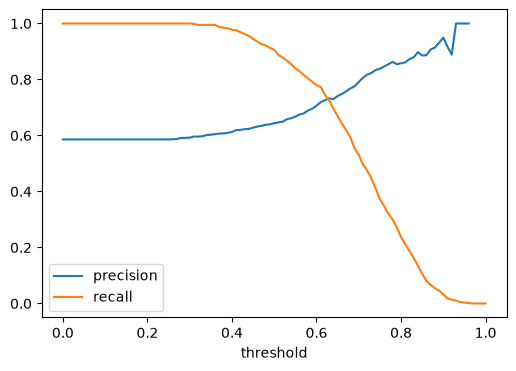

Answer: 0.63


In [14]:
plt.figure(figsize=(6, 4))
plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

valid = scores.dropna(subset=['precision'])
valid = valid[~((valid.precision == 0) & (valid.recall == 0))]

diff = (valid.precision - valid.recall).abs()
threshold = round(float(valid.loc[diff.idxmin(), 'threshold']), 2)
print('Answer:', threshold)

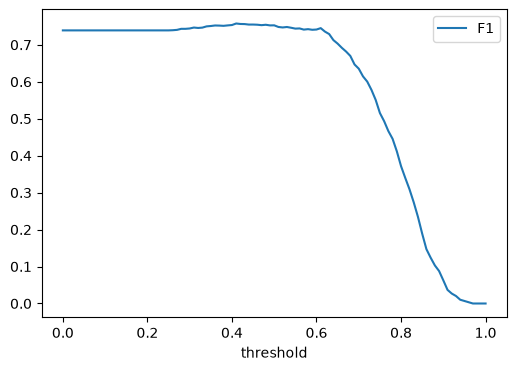

Answer: 0.41


In [15]:
plt.figure(figsize=(6, 4))
plt.plot(scores.threshold, scores.f1, label='F1')
plt.xlabel('threshold')
plt.legend()
plt.show()

f1_threshold = round(float(scores.loc[scores.f1.idxmax(), 'threshold']), 2)
print('Answer:', f1_threshold)

In [17]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

fold_scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    y_tr = df_tr.converted.values
    y_va = df_va.converted.values

    dv_k, model_k = train(df_tr, y_tr, C=1.0)
    y_hat = predict(df_va, dv_k, model_k)
    fold_scores.append(roc_auc_score(y_va, y_hat))

print('fold sizes:', [len(df_full_train.iloc[v]) for _, v in kfold.split(df_full_train)])
print('fold AUCs: ', [round(s, 4) for s in fold_scores])
folds_std = np.std(fold_scores)
print('Answer:', round(folds_std, 3))

fold sizes: [800, 800, 800, 800, 800]
fold AUCs:  [0.7306, 0.7296, 0.7363, 0.7412, 0.7209]
Answer: 0.007


In [21]:
results = []
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores_C = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr.converted.values
        y_va = df_va.converted.values

        dv_k, model_k = train(df_tr, y_tr, C=C)
        y_hat = predict(df_va, dv_k, model_k)
        scores_C.append(roc_auc_score(y_va, y_hat))

    mean_, std_ = round(float(np.mean(scores_C)), 3), round(float(np.std(scores_C)), 3)
    results.append((C, mean_, std_))
    print(f'C = {C:<10} mean = {mean_:.3f}  std = {std_:.3f}')

best = sorted(results, key = lambda r: (-r[1], r[2], r[0]))[0]
print('Answer: C =', best[0])

C = 1e-06      mean = 0.617  std = 0.019
C = 0.001      mean = 0.749  std = 0.010
C = 1          mean = 0.732  std = 0.007
Answer: C = 0.001
